# 04 — Provider Pressure Investigation

## Purpose

This notebook investigates the provider-pressure candidates identified through the controlled eligibility and upper-decile rules established in Notebook 03.

The notebook uses the validated DuckDB analytical layer and does not recreate ingestion, transformation, or governed KPI logic.

## Analytical objectives

- reproduce the investigation-candidate cohort directly from controlled DuckDB views;
- segment candidates into breach-only, DTA-only, and dual-pressure groups;
- examine 25-month provider trajectories;
- compare candidate trajectories with eligible-provider benchmarks;
- evaluate persistence, recent direction, volatility, and peak pressure;
- apply robust outlier analysis using medians and median absolute deviation;
- create a transparent investigation-priority framework;
- prepare Power BI-ready analytical outputs.

The outputs are screening and prioritisation tools. They are not provider league tables and do not establish operational causation.


## 1. Imports and configuration


In [1]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import median_abs_deviation

from nhs_ae.config import PROJECT_PATHS
from nhs_ae.database.connection import database_connection

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

sns.set_theme(style="whitegrid")


## 2. Database and analytical-source validation


In [2]:
database_path = PROJECT_PATHS.database_file

assert database_path.exists(), "DuckDB analytical database is missing."

with database_connection(read_only=True) as connection:
    database_version = connection.execute("SELECT version()").fetchone()

assert database_version is not None

print("PROVIDER PRESSURE DATABASE GATE: PASS")
print("Database:", database_path)
print("DuckDB version:", database_version[0])


PROVIDER PRESSURE DATABASE GATE: PASS
Database: C:\nhs_ae_analytics\data\database\nhs_ae.duckdb
DuckDB version: v2.0.0


In [3]:
with database_connection(read_only=True) as connection:
    provider_pressure = connection.execute(
        """
        SELECT *
        FROM analytics.provider_pressure
        ORDER BY org_code
        """
    ).df()

    provider_monthly = connection.execute(
        """
        SELECT
            reporting_month,
            org_code,
            org_name,
            ae_attendances_type1
                + ae_attendances_type2
                + ae_attendances_other
                + ae_booked_attendances_type1
                + ae_booked_attendances_type2
                + ae_booked_attendances_other
                    AS total_attendances,
            emergency_admissions_ae_type1
                + emergency_admissions_ae_type2
                + emergency_admissions_ae_other
                + other_emergency_admissions
                    AS emergency_admissions,
            ae_over_4hrs_type1
                + ae_over_4hrs_type2
                + ae_over_4hrs_other
                + ae_booked_over_4hrs_type1
                + ae_booked_over_4hrs_type2
                + ae_booked_over_4hrs_other
                    AS four_hour_breaches,
            dta_wait_4_12hrs AS dta_waits_4_12hrs,
            dta_wait_12plus_hrs AS dta_waits_12plus_hrs,
            dta_wait_4_12hrs + dta_wait_12plus_hrs
                AS total_dta_waits_4plus_hrs
        FROM core.provider_monthly
        ORDER BY org_code, reporting_month
        """
    ).df()

provider_monthly["reporting_month"] = pd.to_datetime(
    provider_monthly["reporting_month"]
)

assert provider_pressure.shape == (188, 30)
assert provider_monthly.shape == (4_918, 9)
assert provider_pressure["org_code"].is_unique
assert not provider_monthly.duplicated(
    ["reporting_month", "org_code"]
).any()

print("PROVIDER PRESSURE SOURCES: PASS")
print("Provider pressure:", provider_pressure.shape)
print("Provider-month source:", provider_monthly.shape)


PROVIDER PRESSURE SOURCES: PASS
Provider pressure: (188, 30)
Provider-month source: (4918, 9)


## 3. Reproduce the investigation-candidate cohort

Candidates are reconstructed from the controlled pressure view. A candidate must be eligible for the relevant analysis and fall in the upper decile of the relevant absolute pressure increase.


In [4]:
breach_eligible = provider_pressure.loc[
    provider_pressure["breach_analysis_eligible"]
].copy()

dta_eligible = provider_pressure.loc[
    provider_pressure["dta_analysis_eligible"]
].copy()

breach_threshold = breach_eligible[
    "four_hour_breaches_absolute_change"
].quantile(0.90)

dta_threshold = dta_eligible[
    "dta_waits_12plus_hrs_absolute_change"
].quantile(0.90)

candidate_source = provider_pressure.loc[
    :,
    [
        "org_code",
        "latest_org_name",
        "four_hour_breaches_absolute_change",
        "four_hour_breaches_percentage_change",
        "dta_waits_12plus_hrs_absolute_change",
        "dta_waits_12plus_hrs_percentage_change",
        "breach_analysis_eligible",
        "dta_analysis_eligible",
        "provider_name_changed",
    ],
].copy()

candidate_source["breach_increase_flag"] = (
    candidate_source["breach_analysis_eligible"]
    & (
        candidate_source["four_hour_breaches_absolute_change"]
        >= breach_threshold
    )
)

candidate_source["dta_12plus_increase_flag"] = (
    candidate_source["dta_analysis_eligible"]
    & (
        candidate_source["dta_waits_12plus_hrs_absolute_change"]
        >= dta_threshold
    )
)

investigation_candidates = candidate_source.loc[
    candidate_source["breach_increase_flag"]
    | candidate_source["dta_12plus_increase_flag"]
].copy()

investigation_candidates["candidate_segment"] = np.select(
    [
        investigation_candidates["breach_increase_flag"]
        & investigation_candidates["dta_12plus_increase_flag"],
        investigation_candidates["breach_increase_flag"],
        investigation_candidates["dta_12plus_increase_flag"],
    ],
    [
        "Dual pressure",
        "Breach only",
        "DTA 12+ only",
    ],
    default="Not flagged",
)

investigation_candidates = (
    investigation_candidates
    .sort_values(["candidate_segment", "org_code"])
    .reset_index(drop=True)
)

assert len(investigation_candidates) == 18
assert investigation_candidates["org_code"].is_unique
assert investigation_candidates["candidate_segment"].ne("Not flagged").all()

investigation_candidates


,org_code,latest_org_name,four_hour_breaches_absolute_change,four_hour_breaches_percentage_change,dta_waits_12plus_hrs_absolute_change,dta_waits_12plus_hrs_percentage_change,breach_analysis_eligible,dta_analysis_eligible,provider_name_changed,breach_increase_flag,dta_12plus_increase_flag,candidate_segment
0,REF,ROYAL CORNWALL HOSPITALS NHS TRUST,1502,0.4513,-48,-0.0881,True,True,False,True,False,Breach only
1,RJ2,LEWISHAM AND GREENWICH NHS TRUST,2119,0.2780,115,0.1923,True,True,False,True,False,Breach only
2,RTG,UNIVERSITY HOSPITALS OF DERBY AND BURTON NHS F...,1397,0.1529,237,0.4255,True,True,False,True,False,Breach only
3,RTP,SURREY AND SUSSEX HEALTHCARE NHS TRUST,1372,0.3504,-9,-0.0204,True,True,False,True,False,Breach only
4,RVV,EAST KENT HOSPITALS UNIVERSITY NHS FOUNDATION ...,1302,0.2091,-93,-0.0794,True,True,False,True,False,Breach only
5,RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,2013,0.1780,251,0.4261,True,True,False,True,False,Breach only
6,R1H,BARTS HEALTH NHS TRUST,-152,-0.0123,257,0.2702,True,True,False,False,True,DTA 12+ only
7,RDE,EAST SUFFOLK AND NORTH ESSEX NHS FOUNDATION TRUST,-1096,-0.1493,261,0.4372,True,True,False,False,True,DTA 12+ only
8,RDU,FRIMLEY HEALTH NHS FOUNDATION TRUST,-773,-0.0801,274,0.8431,True,True,False,False,True,DTA 12+ only
9,RMC,BOLTON NHS FOUNDATION TRUST,526,0.1285,367,1.7230,True,True,False,False,True,DTA 12+ only


In [5]:
candidate_segment_summary = (
    investigation_candidates["candidate_segment"]
    .value_counts()
    .rename_axis("candidate_segment")
    .reset_index(name="provider_count")
)

candidate_segment_summary


,candidate_segment,provider_count
0,DTA 12+ only,8
1,Breach only,6
2,Dual pressure,4


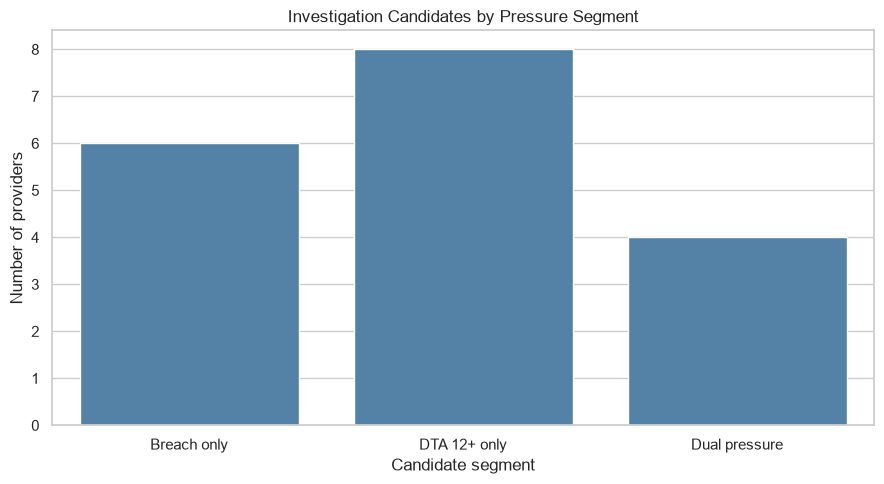

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

segment_order = ["Breach only", "DTA 12+ only", "Dual pressure"]

sns.barplot(
    data=candidate_segment_summary,
    x="candidate_segment",
    y="provider_count",
    order=segment_order,
    color="steelblue",
    ax=ax,
)

ax.set_title("Investigation Candidates by Pressure Segment")
ax.set_xlabel("Candidate segment")
ax.set_ylabel("Number of providers")

fig.tight_layout()
plt.show()


## 4. Candidate longitudinal dataset


In [7]:
candidate_codes = investigation_candidates["org_code"].tolist()

candidate_monthly = (
    provider_monthly.loc[
        provider_monthly["org_code"].isin(candidate_codes)
    ]
    .merge(
        investigation_candidates[
            [
                "org_code",
                "latest_org_name",
                "candidate_segment",
                "provider_name_changed",
            ]
        ],
        on="org_code",
        how="left",
        validate="many_to_one",
    )
    .sort_values(["org_code", "reporting_month"])
    .reset_index(drop=True)
)

candidate_coverage = (
    candidate_monthly.groupby("org_code")["reporting_month"]
    .nunique()
)

assert len(candidate_coverage) == 18
assert candidate_coverage.eq(25).all()
assert candidate_monthly.shape[0] == 18 * 25

print("CANDIDATE LONGITUDINAL DATASET: PASS")
print("Providers:", candidate_monthly["org_code"].nunique())
print("Months:", candidate_monthly["reporting_month"].nunique())
print("Rows:", len(candidate_monthly))

candidate_monthly.head()


CANDIDATE LONGITUDINAL DATASET: PASS
Providers: 18
Months: 25
Rows: 450


,reporting_month,org_code,org_name,total_attendances,emergency_admissions,four_hour_breaches,dta_waits_4_12hrs,dta_waits_12plus_hrs,total_dta_waits_4plus_hrs,latest_org_name,candidate_segment,provider_name_changed
0,2024-09-01,R1H,BARTS HEALTH NHS TRUST,41260,5033,12397,1135,885,2020,BARTS HEALTH NHS TRUST,DTA 12+ only,False
1,2024-10-01,R1H,BARTS HEALTH NHS TRUST,44666,5813,13247,1195,1199,2394,BARTS HEALTH NHS TRUST,DTA 12+ only,False
2,2024-11-01,R1H,BARTS HEALTH NHS TRUST,43897,5633,13160,1139,1064,2203,BARTS HEALTH NHS TRUST,DTA 12+ only,False
3,2024-12-01,R1H,BARTS HEALTH NHS TRUST,45008,5904,13365,1156,1199,2355,BARTS HEALTH NHS TRUST,DTA 12+ only,False
4,2025-01-01,R1H,BARTS HEALTH NHS TRUST,43836,5689,12830,1025,1319,2344,BARTS HEALTH NHS TRUST,DTA 12+ only,False


## 5. Eligible-provider monthly benchmark

Candidate trajectories are compared with medians across providers eligible for the relevant pressure analysis. Medians reduce sensitivity to very large organisations and extreme monthly values.


In [8]:
breach_eligible_codes = set(
    breach_eligible["org_code"]
)

dta_eligible_codes = set(
    dta_eligible["org_code"]
)

breach_benchmark = (
    provider_monthly.loc[
        provider_monthly["org_code"].isin(breach_eligible_codes)
    ]
    .groupby("reporting_month", as_index=False)
    .agg(
        eligible_median_four_hour_breaches=(
            "four_hour_breaches",
            "median",
        ),
        eligible_median_attendances=(
            "total_attendances",
            "median",
        ),
    )
)

dta_benchmark = (
    provider_monthly.loc[
        provider_monthly["org_code"].isin(dta_eligible_codes)
    ]
    .groupby("reporting_month", as_index=False)
    .agg(
        eligible_median_dta_12plus=(
            "dta_waits_12plus_hrs",
            "median",
        ),
        eligible_median_admissions=(
            "emergency_admissions",
            "median",
        ),
    )
)

monthly_benchmark = breach_benchmark.merge(
    dta_benchmark,
    on="reporting_month",
    validate="one_to_one",
)

assert len(monthly_benchmark) == 25

monthly_benchmark.head()


,reporting_month,eligible_median_four_hour_breaches,eligible_median_attendances,eligible_median_dta_12plus,eligible_median_admissions
0,2024-09-01,"4,632.0000","17,032.0000",193.0000,"4,026.0000"
1,2024-10-01,"5,233.0000","18,239.0000",299.0000,"4,241.0000"
2,2024-11-01,"5,292.0000","17,636.0000",263.0000,"4,171.0000"
3,2024-12-01,"5,389.0000","17,631.0000",372.0000,"4,232.0000"
4,2025-01-01,"4,773.0000","16,814.0000",456.0000,"4,129.0000"


## 6. Segment-level longitudinal pressure profiles


In [9]:
segment_monthly = (
    candidate_monthly.groupby(
        ["candidate_segment", "reporting_month"],
        as_index=False,
    )
    .agg(
        providers=("org_code", "nunique"),
        median_four_hour_breaches=("four_hour_breaches", "median"),
        median_dta_12plus_hrs=("dta_waits_12plus_hrs", "median"),
        median_attendances=("total_attendances", "median"),
        median_admissions=("emergency_admissions", "median"),
    )
)

segment_monthly.head()


,candidate_segment,reporting_month,providers,median_four_hour_breaches,median_dta_12plus_hrs,median_attendances,median_admissions
0,Breach only,2024-09-01,6,"7,197.0000",793.0000,"24,551.5000","4,695.0000"
1,Breach only,2024-10-01,6,"7,927.0000",948.5000,"25,875.0000","4,869.5000"
2,Breach only,2024-11-01,6,"7,852.5000",851.5000,"25,668.0000","5,094.0000"
3,Breach only,2024-12-01,6,"8,089.5000",765.5000,"26,390.0000","5,133.5000"
4,Breach only,2025-01-01,6,"7,750.5000",931.0000,"25,127.5000","5,025.0000"


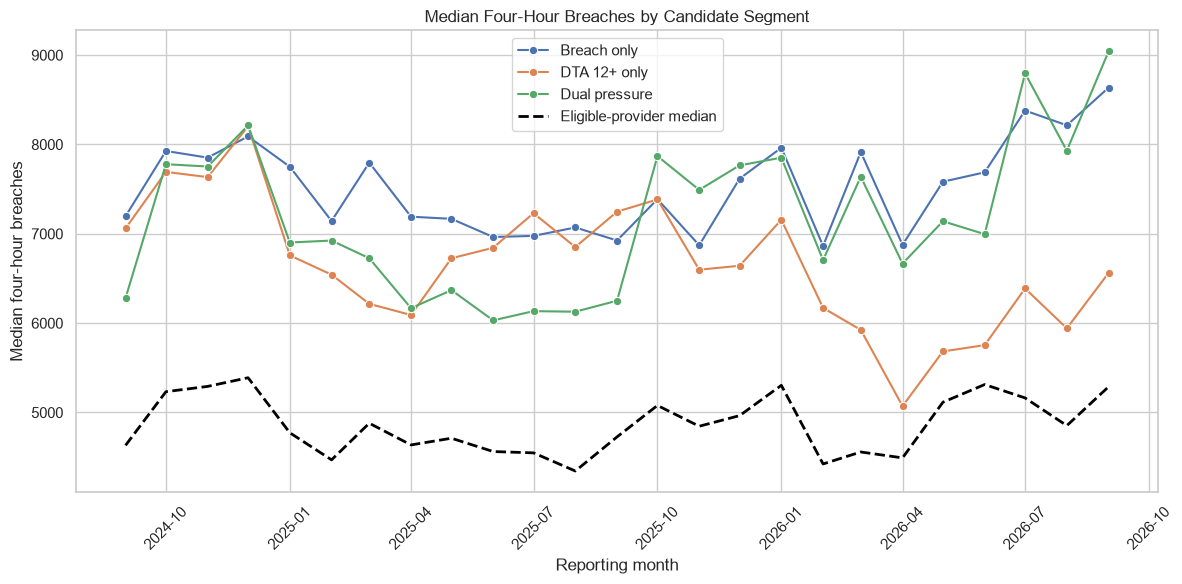

In [11]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=segment_monthly,
    x="reporting_month",
    y="median_four_hour_breaches",
    hue="candidate_segment",
    marker="o",
    ax=ax,
)

ax.plot(
    monthly_benchmark["reporting_month"],
    monthly_benchmark["eligible_median_four_hour_breaches"],
    color="black",
    linestyle="--",
    linewidth=2,
    label="Eligible-provider median",
)

ax.set_title("Median Four-Hour Breaches by Candidate Segment")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Median four-hour breaches")
ax.tick_params(axis="x", rotation=45)
ax.legend()

fig.tight_layout()
plt.show()


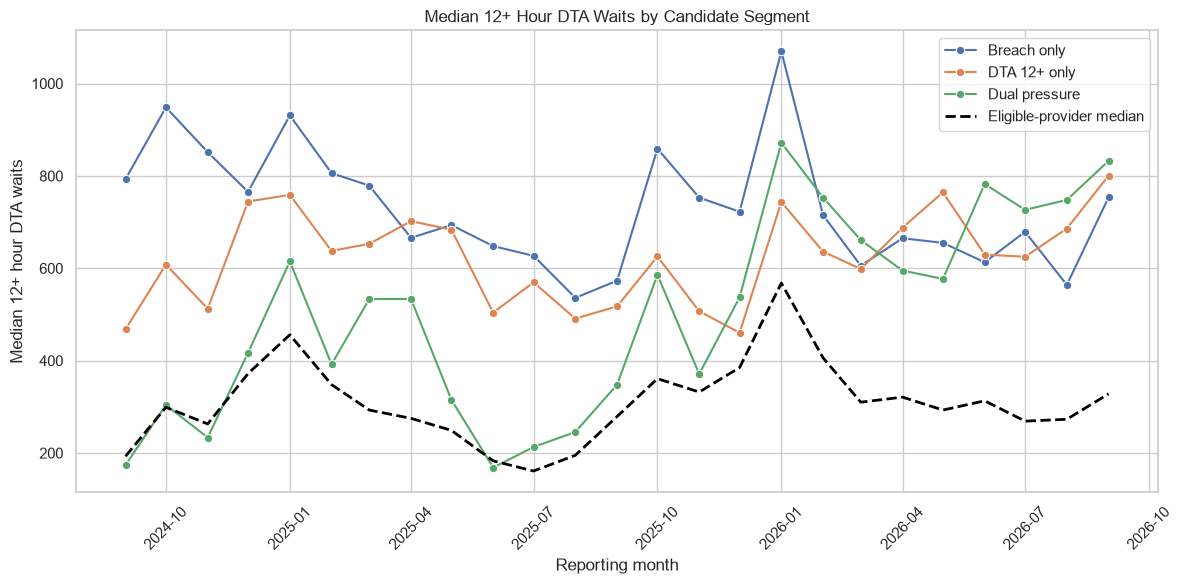

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=segment_monthly,
    x="reporting_month",
    y="median_dta_12plus_hrs",
    hue="candidate_segment",
    marker="o",
    ax=ax,
)

ax.plot(
    monthly_benchmark["reporting_month"],
    monthly_benchmark["eligible_median_dta_12plus"],
    color="black",
    linestyle="--",
    linewidth=2,
    label="Eligible-provider median",
)

ax.set_title("Median 12+ Hour DTA Waits by Candidate Segment")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Median 12+ hour DTA waits")
ax.tick_params(axis="x", rotation=45)
ax.legend()

fig.tight_layout()
plt.show()


## 7. Provider-level trajectory features


In [13]:
def coefficient_of_variation(series: pd.Series) -> float:
    """Return standard deviation divided by mean for a numeric series."""
    mean_value = float(series.mean())
    if mean_value == 0:
        return float("nan")
    return float(series.std(ddof=1) / mean_value)


def recent_slope(group: pd.DataFrame, column: str) -> float:
    """Return the linear monthly slope over the final six observations."""
    recent = group.sort_values("reporting_month").tail(6)
    if len(recent) < 2:
        return float("nan")
    x_values = np.arange(len(recent), dtype=float)
    y_values = recent[column].to_numpy(dtype=float)
    return float(np.polyfit(x_values, y_values, 1)[0])


In [14]:
trajectory_rows = []

for org_code, group in candidate_monthly.groupby("org_code", sort=True):
    ordered = group.sort_values("reporting_month")

    latest_name = ordered["latest_org_name"].iloc[-1]
    segment = ordered["candidate_segment"].iloc[-1]
    name_changed = bool(ordered["provider_name_changed"].iloc[-1])

    breach_median = float(ordered["four_hour_breaches"].median())
    dta_median = float(ordered["dta_waits_12plus_hrs"].median())

    trajectory_rows.append(
        {
            "org_code": org_code,
            "latest_org_name": latest_name,
            "candidate_segment": segment,
            "provider_name_changed": name_changed,
            "months_present": ordered["reporting_month"].nunique(),
            "median_four_hour_breaches": breach_median,
            "peak_four_hour_breaches": int(
                ordered["four_hour_breaches"].max()
            ),
            "peak_breach_month": ordered.loc[
                ordered["four_hour_breaches"].idxmax(),
                "reporting_month",
            ],
            "breach_cv": coefficient_of_variation(
                ordered["four_hour_breaches"]
            ),
            "breach_recent_6m_slope": recent_slope(
                ordered,
                "four_hour_breaches",
            ),
            "months_above_breach_median": int(
                ordered["four_hour_breaches"].gt(breach_median).sum()
            ),
            "median_dta_12plus_hrs": dta_median,
            "peak_dta_12plus_hrs": int(
                ordered["dta_waits_12plus_hrs"].max()
            ),
            "peak_dta_month": ordered.loc[
                ordered["dta_waits_12plus_hrs"].idxmax(),
                "reporting_month",
            ],
            "dta_12plus_cv": coefficient_of_variation(
                ordered["dta_waits_12plus_hrs"]
            ),
            "dta_recent_6m_slope": recent_slope(
                ordered,
                "dta_waits_12plus_hrs",
            ),
            "months_above_dta_median": int(
                ordered["dta_waits_12plus_hrs"].gt(dta_median).sum()
            ),
        }
    )

trajectory_features = pd.DataFrame(trajectory_rows)

assert trajectory_features.shape[0] == 18
assert trajectory_features["org_code"].is_unique
assert trajectory_features["months_present"].eq(25).all()

trajectory_features


,org_code,latest_org_name,candidate_segment,provider_name_changed,months_present,median_four_hour_breaches,peak_four_hour_breaches,peak_breach_month,breach_cv,breach_recent_6m_slope,months_above_breach_median,median_dta_12plus_hrs,peak_dta_12plus_hrs,peak_dta_month,dta_12plus_cv,dta_recent_6m_slope,months_above_dta_median
0,R1H,BARTS HEALTH NHS TRUST,DTA 12+ only,False,25,"12,563.0000",14009,2025-11-01,0.0733,155.8000,12,"1,148.0000",1352,2026-01-01,0.1354,11.0857,12
1,RA7,BRISTOL NHS FOUNDATION TRUST,Dual pressure,True,25,"5,846.0000",9260,2026-07-01,0.1660,757.2000,12,486.0000,909,2025-01-01,0.4474,57.5429,12
2,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,Dual pressure,False,25,"10,832.0000",13046,2024-12-01,0.1205,435.3429,12,627.0000,1371,2026-08-01,0.6422,116.8286,12
3,RDE,EAST SUFFOLK AND NORTH ESSEX NHS FOUNDATION TRUST,DTA 12+ only,False,25,"6,274.0000",8015,2024-12-01,0.1115,97.6857,12,548.0000,885,2025-01-01,0.2835,72.8571,12
4,RDU,FRIMLEY HEALTH NHS FOUNDATION TRUST,DTA 12+ only,False,25,"9,654.0000",11428,2024-10-01,0.0898,132.3714,12,437.0000,756,2026-05-01,0.3892,-46.4571,12
5,REF,ROYAL CORNWALL HOSPITALS NHS TRUST,Breach only,False,25,"4,132.0000",5816,2026-07-01,0.1584,160.6000,12,545.0000,773,2026-01-01,0.2565,-20.3714,12
6,RJ2,LEWISHAM AND GREENWICH NHS TRUST,Breach only,False,25,"8,555.0000",9742,2026-09-01,0.0742,309.2857,12,703.0000,943,2026-01-01,0.1817,42.6857,12
7,RMC,BOLTON NHS FOUNDATION TRUST,DTA 12+ only,False,25,"4,045.0000",4913,2025-11-01,0.1056,164.2286,12,455.0000,675,2024-10-01,0.3063,10.6286,12
8,RN7,DARTFORD AND GRAVESHAM NHS TRUST,DTA 12+ only,False,25,"3,081.0000",4492,2024-12-01,0.1686,106.3143,12,342.0000,579,2025-05-01,0.4797,13.1429,12
9,RNQ,KETTERING GENERAL HOSPITAL NHS FOUNDATION TRUST,DTA 12+ only,False,25,"3,895.0000",4787,2024-12-01,0.0718,68.6286,12,626.0000,891,2025-03-01,0.6118,9.5714,12


## 8. Persistence and recent direction

Persistence counts how many months each provider exceeded its own 25-month median. Recent slopes describe the direction of the final six monthly observations. These measures support investigation prioritisation but are not causal indicators.


In [15]:
persistence_summary = trajectory_features.loc[
    :,
    [
        "org_code",
        "latest_org_name",
        "candidate_segment",
        "months_above_breach_median",
        "months_above_dta_median",
        "breach_recent_6m_slope",
        "dta_recent_6m_slope",
        "provider_name_changed",
    ],
].sort_values(
    [
        "months_above_breach_median",
        "months_above_dta_median",
        "org_code",
    ],
    ascending=[False, False, True],
).reset_index(drop=True)

persistence_summary


,org_code,latest_org_name,candidate_segment,months_above_breach_median,months_above_dta_median,breach_recent_6m_slope,dta_recent_6m_slope,provider_name_changed
0,R1H,BARTS HEALTH NHS TRUST,DTA 12+ only,12,12,155.8000,11.0857,False
1,RA7,BRISTOL NHS FOUNDATION TRUST,Dual pressure,12,12,757.2000,57.5429,True
2,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,Dual pressure,12,12,435.3429,116.8286,False
3,RDE,EAST SUFFOLK AND NORTH ESSEX NHS FOUNDATION TRUST,DTA 12+ only,12,12,97.6857,72.8571,False
4,RDU,FRIMLEY HEALTH NHS FOUNDATION TRUST,DTA 12+ only,12,12,132.3714,-46.4571,False
5,REF,ROYAL CORNWALL HOSPITALS NHS TRUST,Breach only,12,12,160.6000,-20.3714,False
6,RJ2,LEWISHAM AND GREENWICH NHS TRUST,Breach only,12,12,309.2857,42.6857,False
7,RMC,BOLTON NHS FOUNDATION TRUST,DTA 12+ only,12,12,164.2286,10.6286,False
8,RN7,DARTFORD AND GRAVESHAM NHS TRUST,DTA 12+ only,12,12,106.3143,13.1429,False
9,RNQ,KETTERING GENERAL HOSPITAL NHS FOUNDATION TRUST,DTA 12+ only,12,12,68.6286,9.5714,False


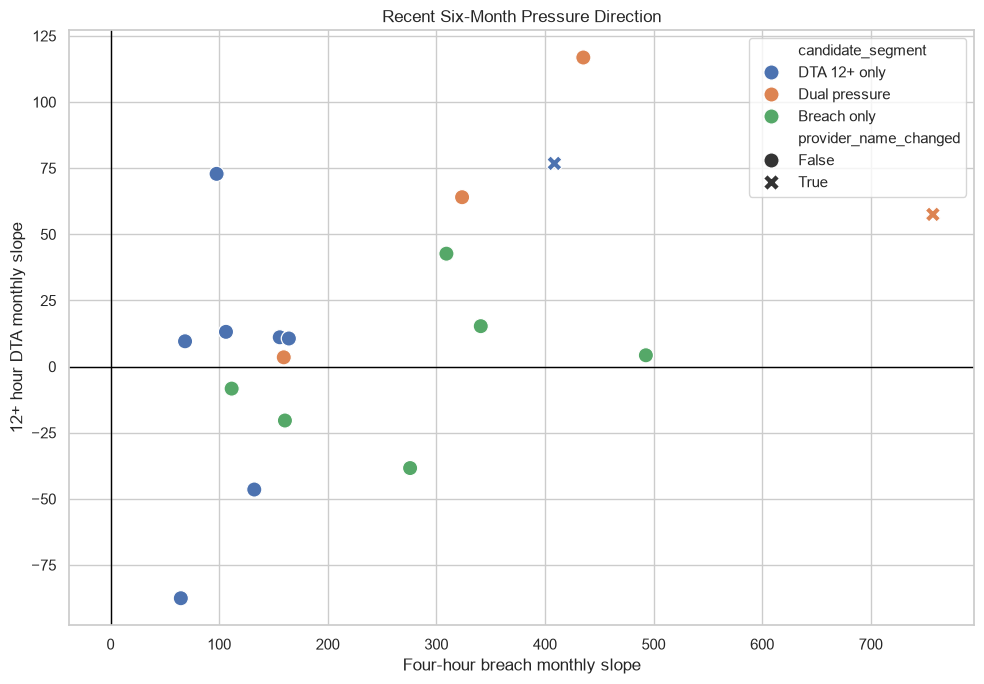

In [16]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    data=trajectory_features,
    x="breach_recent_6m_slope",
    y="dta_recent_6m_slope",
    hue="candidate_segment",
    style="provider_name_changed",
    s=120,
    ax=ax,
)

ax.axvline(0, color="black", linewidth=1)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Recent Six-Month Pressure Direction")
ax.set_xlabel("Four-hour breach monthly slope")
ax.set_ylabel("12+ hour DTA monthly slope")

fig.tight_layout()
plt.show()


## 9. Robust outlier analysis


In [17]:
def robust_z_score(series: pd.Series) -> pd.Series:
    """Return modified z-scores based on the median absolute deviation."""
    median_value = float(series.median())
    mad_value = float(
        median_abs_deviation(
            series,
            scale=1.0,
            nan_policy="omit",
        )
    )

    if mad_value == 0:
        return pd.Series(
            np.zeros(len(series), dtype=float),
            index=series.index,
        )

    return 0.6745 * (series - median_value) / mad_value


In [18]:
robust_analysis = investigation_candidates.merge(
    trajectory_features,
    on=[
        "org_code",
        "latest_org_name",
        "candidate_segment",
        "provider_name_changed",
    ],
    how="left",
    validate="one_to_one",
)

robust_analysis["breach_change_robust_z"] = robust_z_score(
    robust_analysis["four_hour_breaches_absolute_change"]
)

robust_analysis["dta_change_robust_z"] = robust_z_score(
    robust_analysis["dta_waits_12plus_hrs_absolute_change"]
)

robust_analysis["robust_outlier_flag"] = (
    robust_analysis["breach_change_robust_z"].abs().ge(3.5)
    | robust_analysis["dta_change_robust_z"].abs().ge(3.5)
)

robust_outliers = robust_analysis.loc[
    robust_analysis["robust_outlier_flag"]
].sort_values(
    ["breach_change_robust_z", "dta_change_robust_z"],
    ascending=False,
)

robust_outliers


,org_code,latest_org_name,four_hour_breaches_absolute_change,four_hour_breaches_percentage_change,dta_waits_12plus_hrs_absolute_change,dta_waits_12plus_hrs_percentage_change,breach_analysis_eligible,dta_analysis_eligible,provider_name_changed,breach_increase_flag,dta_12plus_increase_flag,candidate_segment,months_present,median_four_hour_breaches,peak_four_hour_breaches,peak_breach_month,breach_cv,breach_recent_6m_slope,months_above_breach_median,median_dta_12plus_hrs,peak_dta_12plus_hrs,peak_dta_month,dta_12plus_cv,dta_recent_6m_slope,months_above_dta_median,breach_change_robust_z,dta_change_robust_z,robust_outlier_flag
15,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,2446,0.2766,888,1.8385,True,True,False,True,True,Dual pressure,25,"10,832.0000",13046,2024-12-01,0.1205,435.3429,12,627.0000,1371,2026-08-01,0.6422,116.8286,12,1.0261,4.4606,True


## 10. Transparent investigation priority


In [19]:
priority_frame = robust_analysis.copy()

priority_frame["dual_pressure_points"] = (
    priority_frame["candidate_segment"].eq("Dual pressure").astype(int) * 2
)

priority_frame["recent_breach_increase_points"] = (
    priority_frame["breach_recent_6m_slope"].gt(0).astype(int)
)

priority_frame["recent_dta_increase_points"] = (
    priority_frame["dta_recent_6m_slope"].gt(0).astype(int)
)

priority_frame["breach_persistence_points"] = (
    priority_frame["months_above_breach_median"].ge(12).astype(int)
)

priority_frame["dta_persistence_points"] = (
    priority_frame["months_above_dta_median"].ge(12).astype(int)
)

priority_frame["robust_outlier_points"] = (
    priority_frame["robust_outlier_flag"].astype(int)
)

score_columns = [
    "dual_pressure_points",
    "recent_breach_increase_points",
    "recent_dta_increase_points",
    "breach_persistence_points",
    "dta_persistence_points",
    "robust_outlier_points",
]

priority_frame["investigation_priority_score"] = priority_frame[
    score_columns
].sum(axis=1)

priority_frame["priority_band"] = pd.cut(
    priority_frame["investigation_priority_score"],
    bins=[-1, 2, 4, 7],
    labels=["Standard", "Elevated", "High"],
)

investigation_priority = (
    priority_frame.loc[
        :,
        [
            "org_code",
            "latest_org_name",
            "candidate_segment",
            "provider_name_changed",
            "four_hour_breaches_absolute_change",
            "dta_waits_12plus_hrs_absolute_change",
            "breach_recent_6m_slope",
            "dta_recent_6m_slope",
            "months_above_breach_median",
            "months_above_dta_median",
            "robust_outlier_flag",
            "investigation_priority_score",
            "priority_band",
        ],
    ]
    .sort_values(
        [
            "investigation_priority_score",
            "candidate_segment",
            "org_code",
        ],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)

investigation_priority


,org_code,latest_org_name,candidate_segment,provider_name_changed,four_hour_breaches_absolute_change,dta_waits_12plus_hrs_absolute_change,breach_recent_6m_slope,dta_recent_6m_slope,months_above_breach_median,months_above_dta_median,robust_outlier_flag,investigation_priority_score,priority_band
0,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,Dual pressure,False,2446,888,435.3429,116.8286,12,12,True,7,High
1,RA7,BRISTOL NHS FOUNDATION TRUST,Dual pressure,True,3264,407,757.2000,57.5429,12,12,False,6,High
2,RWF,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,Dual pressure,False,1546,590,323.7143,64.0286,12,12,False,6,High
3,RX1,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,Dual pressure,False,2316,345,159.5143,3.5143,12,12,False,6,High
4,RJ2,LEWISHAM AND GREENWICH NHS TRUST,Breach only,False,2119,115,309.2857,42.6857,12,12,False,4,Elevated
5,RVV,EAST KENT HOSPITALS UNIVERSITY NHS FOUNDATION ...,Breach only,False,1302,-93,340.9143,15.2857,12,12,False,4,Elevated
6,RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,Breach only,False,2013,251,492.9429,4.2857,12,12,False,4,Elevated
7,R1H,BARTS HEALTH NHS TRUST,DTA 12+ only,False,-152,257,155.8000,11.0857,12,12,False,4,Elevated
8,RDE,EAST SUFFOLK AND NORTH ESSEX NHS FOUNDATION TRUST,DTA 12+ only,False,-1096,261,97.6857,72.8571,12,12,False,4,Elevated
9,RMC,BOLTON NHS FOUNDATION TRUST,DTA 12+ only,False,526,367,164.2286,10.6286,12,12,False,4,Elevated


### Priority-score interpretation

The score is a transparent screening aid, not a validated clinical or regulatory risk model.

- Dual-pressure candidates receive two points.
- Positive recent breach and DTA slopes receive one point each.
- Persistent above-median breach and DTA pressure receive one point each.
- A robust outlier flag receives one point.

The score prioritises follow-up; it does not judge provider performance or explain causes.


In [20]:
priority_summary = (
    investigation_priority["priority_band"]
    .value_counts(dropna=False)
    .rename_axis("priority_band")
    .reset_index(name="provider_count")
)

priority_summary


,priority_band,provider_count
0,Elevated,14
1,High,4
2,Standard,0


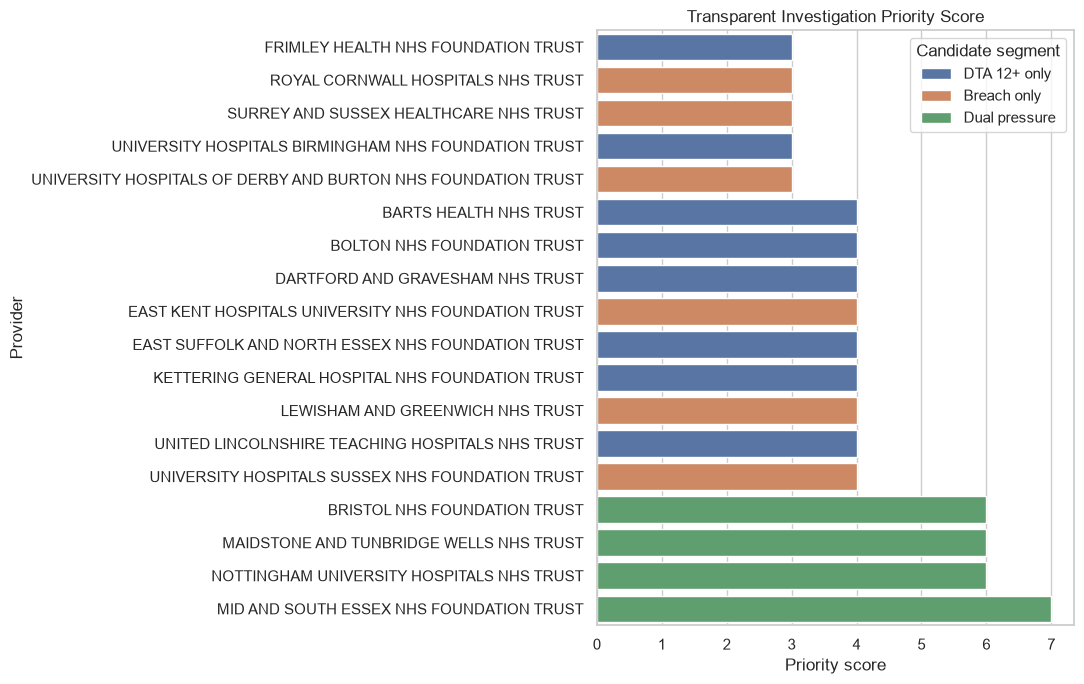

In [21]:
fig, ax = plt.subplots(figsize=(11, 7))

plot_data = investigation_priority.sort_values(
    ["investigation_priority_score", "latest_org_name"],
    ascending=[True, True],
)

sns.barplot(
    data=plot_data,
    x="investigation_priority_score",
    y="latest_org_name",
    hue="candidate_segment",
    dodge=False,
    ax=ax,
)

ax.set_title("Transparent Investigation Priority Score")
ax.set_xlabel("Priority score")
ax.set_ylabel("Provider")
ax.legend(title="Candidate segment")

fig.tight_layout()
plt.show()


## 11. Power BI-ready outputs


In [22]:
powerbi_candidate_summary = investigation_priority.copy()

powerbi_candidate_monthly = candidate_monthly.loc[
    :,
    [
        "reporting_month",
        "org_code",
        "latest_org_name",
        "candidate_segment",
        "provider_name_changed",
        "total_attendances",
        "emergency_admissions",
        "four_hour_breaches",
        "dta_waits_4_12hrs",
        "dta_waits_12plus_hrs",
        "total_dta_waits_4plus_hrs",
    ],
].copy()

assert powerbi_candidate_summary["org_code"].is_unique
assert len(powerbi_candidate_monthly) == 450
assert not powerbi_candidate_monthly.duplicated(
    ["reporting_month", "org_code"]
).any()

print("POWER BI OUTPUT PREPARATION: PASS")
print("Candidate summary rows:", len(powerbi_candidate_summary))
print("Candidate monthly rows:", len(powerbi_candidate_monthly))


POWER BI OUTPUT PREPARATION: PASS
Candidate summary rows: 18
Candidate monthly rows: 450


In [23]:
output_directory = PROJECT_PATHS.analytical
output_directory.mkdir(parents=True, exist_ok=True)

candidate_summary_path = (
    output_directory / "provider_investigation_priority.csv"
)

candidate_monthly_path = (
    output_directory / "provider_investigation_monthly.csv"
)

powerbi_candidate_summary.to_csv(
    candidate_summary_path,
    index=False,
)

powerbi_candidate_monthly.to_csv(
    candidate_monthly_path,
    index=False,
)

assert candidate_summary_path.exists()
assert candidate_monthly_path.exists()

print("POWER BI OUTPUT WRITE: PASS")
print("Summary:", candidate_summary_path)
print("Monthly:", candidate_monthly_path)


POWER BI OUTPUT WRITE: PASS
Summary: C:\nhs_ae_analytics\data\analytical\provider_investigation_priority.csv
Monthly: C:\nhs_ae_analytics\data\analytical\provider_investigation_monthly.csv


## 12. Final notebook validation


In [24]:
assert provider_pressure.shape == (188, 30)
assert provider_monthly.shape == (4_918, 9)
assert investigation_candidates.shape[0] == 18
assert candidate_segment_summary["provider_count"].sum() == 18
assert candidate_monthly.shape[0] == 450
assert candidate_monthly["org_code"].nunique() == 18
assert candidate_monthly["reporting_month"].nunique() == 25
assert trajectory_features.shape[0] == 18
assert investigation_priority.shape[0] == 18
assert investigation_priority["org_code"].is_unique
assert powerbi_candidate_summary.shape[0] == 18
assert powerbi_candidate_monthly.shape[0] == 450
assert candidate_summary_path.exists()
assert candidate_monthly_path.exists()

print("PROVIDER PRESSURE INVESTIGATION VALIDATION: PASS")
print("Candidates:", len(investigation_candidates))
print("Candidate monthly rows:", len(candidate_monthly))
print("Trajectory feature rows:", len(trajectory_features))
print("Priority rows:", len(investigation_priority))
print("Robust outliers:", int(robust_analysis["robust_outlier_flag"].sum()))
print("Power BI outputs:", 2)


PROVIDER PRESSURE INVESTIGATION VALIDATION: PASS
Candidates: 18
Candidate monthly rows: 450
Trajectory feature rows: 18
Priority rows: 18
Robust outliers: 1
Power BI outputs: 2


## 13. Interpretation guardrails and limitations

- Candidate inclusion is based on controlled upper-decile change rules and eligibility thresholds.
- The candidate cohort is intentionally selective and is not representative of all providers.
- Provider scale, service configuration, case mix, and local context remain important.
- Recent slopes are descriptive linear summaries of six observations.
- Median-based persistence is relative to each provider's own history.
- Robust outlier flags identify unusual change within the 18-candidate cohort only.
- The priority score is transparent but not externally validated.
- Provider-name changes require governance review.
- Monthly aggregated data cannot establish operational causes.
- All candidates require local validation before decision-making.


## 14. Notebook completion

This notebook converts the controlled provider-pressure screening results into longitudinal candidate profiles, robust outlier evidence, a transparent investigation-priority framework, and Power BI-ready outputs.

The notebook preserves the distinction between screening, statistical description, and causal interpretation.
